# Machine Learning Homework - Group 22
## Notebook 01 - Import & Explore  (3 pts)

**Objective.** Inspect `train.csv` and the auxiliary `clientes.csv`, describe the
observations and variables, provide descriptive statistics, check data quality and
inconsistencies, and explore univariate and multivariate relationships.

**Inputs.** `data/train.csv`, `data/test.csv`, `data/clientes.csv`, `data/sample_submission.csv`
(read-only submission template from the instructor - it defines the Kaggle output format)
**Outputs.** `data/train_raw.csv`, `data/test_raw.csv`, `data/clientes_raw.csv`

---
### Why this order
The sections follow the exploration sequence taught in the course (Week 03):
first understand the *structure* of the data, then the *target*, then *quality*,
then *relationships*. We inspect the real columns before naming or labelling them.

1. Setup (imports, paths, theme)
2. Load the inputs and verify the submission template
3. Structural survey - shape, dtypes, first rows
4. Column roles - identifiers, target, numeric, categorical, dates; identifier ratio; schema alignment
5. Plot labels (defined only after the columns are known)
6. Duplicates & key integrity (before computing any statistic)
7. Target distribution, balance verdict, baseline
8. Missing data - column axis, row axis, structural nulls
9. Invalid values - 1e9 sentinels and impossible negatives
10. Numeric distributions - every feature: summary table + standardised boxplots
11. Histograms + IQR fences - every numeric feature (6 panels per figure, purely mechanical)
12. Categorical levels & placeholder audit - every level of every column listed
13. Numeric-to-target association (point-biserial) - all features, table + bar chart
14. Predictor redundancy across ALL numeric predictors (multicollinearity heatmap)
15. Categorical-to-target association (Cramer's V) - all features + rate panel per feature
16. Customer metadata (`clientes`) profile, join coverage, every analysable attribute
17. Train vs test covariate shift (descriptive, all features)
18. Key takeaways (auto-computed)
19. Serialize raw frames for Notebook 02

**Coverage rule.** No analysis here silently drops features: every table and figure covers all
29 numeric and all 6 categorical features. Where a display limit is unavoidable (panels per
figure, bars per panel, minimum group size n), the rule and what it excludes are printed next
to the output rather than left implicit.

**Conventions.** Exploration is read-only: nothing is fitted on `test`, and no random
process is used here (the project seed `RANDOM_STATE = 42` appears in Notebooks 03 and 04).
All printed text is ASCII so it renders on any console.

### Cell 1 - Environment
**Purpose.** Import the toolkit, fix the paths, and set one visual language for every figure.
**Method.** `Path.cwd()` is the only path helper used, because notebooks run from inside
`01_notebooks/`. Colours are constants so blue always means the same thing later.
**Look at.** The resolved `data/` path printed at the bottom - it confirms the folder layout.

In [1]:
# CELL 1 - Setup: imports, paths, and plotting theme.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, pointbiserialr
from scipy.stats.contingency import association

# Notebooks are run from inside 01_notebooks/, so the repo root is the parent folder.
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
ARTIFACTS_DIR = ROOT / "artifacts"
FIG_DIR = ARTIFACTS_DIR / "figures"   # pre-created in the repo; notebooks never make folders

TARGET = "repeat_purchase_90d"

# Colorblind-safe palette used consistently across every figure.
PLOT_BLUE = "#1779A8"
PLOT_ORANGE = "#C96A00"

def guide(ax, text):
    # Append a "how to read" caption to the axes title, so a figure still explains itself
    # when it is printed on a page or opened on its own.
    ax.set_title(ax.get_title() + "\n" + text, fontsize=9)

sns.set_theme(style="whitegrid")
print("Environment ready.")
print("  repo root :", ROOT)
print("  data dir  :", DATA_DIR)

Environment ready.
  repo root : C:\Users\Mohamed_Triki\Desktop\Projets\machine_learning\ML_Group_22
  data dir  : C:\Users\Mohamed_Triki\Desktop\Projets\machine_learning\ML_Group_22\data


### Cell 2 - Loading the four supplied files
**Purpose.** Read the raw inputs and confirm the prediction target exists where it should.
**Method.** `train.csv`, `test.csv` and `clientes.csv` are modelling inputs;
`sample_submission.csv` is the instructor's read-only template and is read only to verify the
Kaggle output contract (columns and IDs).
**Look at.** `target in test: False` (test is unlabeled) and the three contract lines at the end.

In [2]:
# CELL 2 - Load the supplied files and confirm the target column.
# train.csv / test.csv / clientes.csv are the modelling inputs.
# sample_submission.csv is the instructor's read-only template: it carries NO features,
# only (ID, repeat_purchase_90d). We read it purely to verify the Kaggle output contract.
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
clientes = pd.read_csv(DATA_DIR / "clientes.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")

print("=== Dimensions (rows, columns) ===")
print("  train        :", train.shape)
print("  test         :", test.shape)
print("  clientes     :", clientes.shape)
print("  sample_sub   :", sample_sub.shape, "(submission template, not a dataset)")

print("\n=== Target ===")
print("  target in train :", TARGET in train.columns)
print("  target in test  :", TARGET in test.columns, "(test is unlabeled)")
print("  target values   :", sorted(train[TARGET].unique()))

print("\n=== Submission contract (from sample_submission.csv) ===")
print("  columns            :", list(sample_sub.columns))
print("  expected columns   : ['ID', 'repeat_purchase_90d']")
print("  cols match expected:", list(sample_sub.columns) == ["ID", TARGET])
print("  #template IDs      :", sample_sub["ID"].nunique())
print("  #test IDs          :", test["ID"].nunique())
print("  IDs identical to test (same order):", list(sample_sub["ID"]) == list(test["ID"]))
print("  -> our NB04 output must be exactly these IDs with a 0/1 prediction each.")

=== Dimensions (rows, columns) ===
  train        : (6534, 39)
  test         : (986, 38)
  clientes     : (1143, 13)
  sample_sub   : (986, 2) (submission template, not a dataset)

=== Target ===
  target in train : True
  target in test  : False (test is unlabeled)
  target values   : [np.int64(0), np.int64(1)]

=== Submission contract (from sample_submission.csv) ===
  columns            : ['ID', 'repeat_purchase_90d']
  expected columns   : ['ID', 'repeat_purchase_90d']
  cols match expected: True
  #template IDs      : 986
  #test IDs          : 986
  IDs identical to test (same order): True
  -> our NB04 output must be exactly these IDs with a 0/1 prediction each.


### Cell 3 - Structural survey
**Purpose.** See what is actually in the data before naming or classifying anything.
**Method.** dtypes plus the first rows. No judgement yet - roles come in the next cell.
**Look at.** Which columns arrived as `object` that look numeric, and the Portuguese column names.

In [3]:
# CELL 3 - Structural survey: what is actually in the data (dtypes and first rows).
print("=== train columns and dtypes ===")
print(train.dtypes.to_string())
print("\nFirst 5 rows of train:")
train.head()

=== train columns and dtypes ===
Total a Pagar                     float64
Total Bruto                       float64
Total Liquido                     float64
Total Imp_                        float64
Total Portes                      float64
Total Desc_ Global                float64
Total Desc_ Linha                 float64
Custo                             float64
N_ Detalhes                       float64
invoice_count_current_purchase    float64
repeat_purchase_90d                 int64
days_since_previous_purchase      float64
customer_tenure_days              float64
prior_purchase_count              float64
prior_total_spend                 float64
prior_mean_purchase_value         float64
prior_std_purchase_value          float64
prior_min_purchase_value          float64
prior_max_purchase_value          float64
prior_mean_gap_days               float64
prior_std_gap_days                float64
purchase_count_30d                float64
spend_30d                         float64
p

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890


### Cell 4 - Column roles
**Purpose.** Decide how each column will be treated: identifier, target, date, numeric, categorical.
**Method.** An identifier ratio (`nunique / rows`) near 1.0 marks a key rather than a feature, so
`ID` and `customer_id` are excluded from the model automatically. Train and test schemas are
compared once the target is removed.
**Look at.** The identifier ratios, the categorical list, and `columns only in train/test`.

In [4]:
# CELL 4 - Column roles. Roles (not dtypes) decide how a column is treated later.
# Identifier-like columns are treated critically and never fed to a model automatically.
id_cols = ["ID", "customer_id"]
date_cols = ["purchase_date"]

numeric_all = train.select_dtypes("number").columns.tolist()
categorical_cols = [c for c in train.select_dtypes("object").columns if c not in date_cols]
feature_numeric = [c for c in numeric_all if c != TARGET and c not in id_cols]

rows = len(train)
print("=== Identifier ratio (nunique / rows); ~1.0 means an identifier, not a feature ===")
for c in id_cols:
    print("  {:12s}: {:.3f}  ({:,} unique of {:,} rows)".format(c, train[c].nunique() / rows, train[c].nunique(), rows))

print("\n=== Column counts by role (train) ===")
print("  identifiers   :", id_cols)
print("  target        :", TARGET)
print("  date (text)   :", date_cols)
print("  numeric feats :", len(feature_numeric))
print("  categorical   :", len(categorical_cols), categorical_cols)

# Schema must match between train and test once the target is removed.
only_train = sorted(set(train.columns) - set(test.columns) - {TARGET})
only_test = sorted(set(test.columns) - set(train.columns))
print("\n=== Schema alignment ===")
print("  columns only in train (besides target):", only_train if only_train else "none")
print("  columns only in test                 :", only_test if only_test else "none")
print("\nUnit of observation: one row = one purchase transaction (ID unique; customer_id repeats).")
print("Per-level detail for each categorical column follows in Cell 12 (not repeated here).")

=== Identifier ratio (nunique / rows); ~1.0 means an identifier, not a feature ===
  ID          : 1.000  (6,534 unique of 6,534 rows)
  customer_id : 0.093  (610 unique of 6,534 rows)

=== Column counts by role (train) ===
  identifiers   : ['ID', 'customer_id']
  target        : repeat_purchase_90d
  date (text)   : ['purchase_date']
  numeric feats : 29
  categorical   : 6 ['payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series']

=== Schema alignment ===
  columns only in train (besides target): none
  columns only in test                 : none

Unit of observation: one row = one purchase transaction (ID unique; customer_id repeats).
Per-level detail for each categorical column follows in Cell 12 (not repeated here).


### Cell 5 - Human-readable labels
**Purpose.** Map every raw column name to a label used in all later tables and figures.
**Method.** A dictionary plus a fallback that title-cases unknown names, defined **after** the
columns were inspected so no label is invented for a column that does not exist.
**Look at.** `train columns without an explicit label: none` - that line is the coverage proof.

In [5]:
# CELL 5 - Human-readable plot labels.
# Defined AFTER inspecting the real columns, and we verify every train column is covered.
FEATURE_LABELS = {
    "Total a Pagar": "Total Payable (EUR)",
    "Total Bruto": "Gross Total (EUR)",
    "Total Liquido": "Net Total (EUR)",
    "Total Imp_": "Tax Total (EUR)",
    "Total Portes": "Shipping Cost (EUR)",
    "Total Desc_ Global": "Global Discount (EUR)",
    "Total Desc_ Linha": "Line Discount (EUR)",
    "Custo": "Cost of Goods (EUR)",
    "N_ Detalhes": "Number of Line Items",
    "invoice_count_current_purchase": "Invoice Count in Purchase",
    "repeat_purchase_90d": "Repeat Purchase within 90 Days",
    "days_since_previous_purchase": "Days Since Previous Purchase",
    "customer_tenure_days": "Customer Tenure (Days)",
    "prior_purchase_count": "Prior Purchase Count",
    "prior_total_spend": "Prior Total Spend (EUR)",
    "prior_mean_purchase_value": "Prior Mean Purchase Value (EUR)",
    "prior_std_purchase_value": "Prior Std Purchase Value (EUR)",
    "prior_min_purchase_value": "Prior Min Purchase Value (EUR)",
    "prior_max_purchase_value": "Prior Max Purchase Value (EUR)",
    "prior_mean_gap_days": "Prior Mean Purchase Gap (Days)",
    "prior_std_gap_days": "Prior Std Purchase Gap (Days)",
    "purchase_count_30d": "Purchase Count (Past 30d)",
    "spend_30d": "Spend (Past 30d, EUR)",
    "purchase_count_90d": "Purchase Count (Past 90d)",
    "spend_90d": "Spend (Past 90d, EUR)",
    "purchase_count_180d": "Purchase Count (Past 180d)",
    "spend_180d": "Spend (Past 180d, EUR)",
    "purchase_count_365d": "Purchase Count (Past 365d)",
    "spend_365d": "Spend (Past 365d, EUR)",
    "random_noise": "Random Noise (planted)",
    "customer_id": "Customer ID",
    "customer_since_year": "Customer Since (Year)",
    "payment_type": "Payment Method",
    "transport_method": "Transport Method",
    "commercial_zone": "Commercial Zone",
    "salesperson": "Salesperson Code",
    "warehouse": "Warehouse Location",
    "document_series": "Document Series",
    "commercial_region": "Commercial Region",
    "country_or_region": "Country / Region",
}


def clean_label(col):
    # Return a readable label, falling back to a title-cased column name.
    return FEATURE_LABELS.get(col, col.replace("_", " ").title())


uncovered = [c for c in train.columns if c not in FEATURE_LABELS and c != "ID"]
print("Labels defined for", len(FEATURE_LABELS), "columns.")
print("train columns without an explicit label:", uncovered if uncovered else "none (ID excluded)")

Labels defined for 40 columns.
train columns without an explicit label: ['purchase_date']


### Cell 6 - Duplicates and key integrity
**Purpose.** Check for repeated rows and repeated keys before computing any statistic, because a
duplicate silently weights every number that follows, and because a test transaction that is really a
copy of a training transaction would make the submission meaningless.
**Method.** Exact duplicate counts, uniqueness of `ID` and of `clientes.customer_id`, duplicate
transactions measured on the **recorded columns only** (`ID` excluded, since IDs are unique by
construction), and a cross-file comparison of training and test transactions. Then the distribution of
transactions per customer.
**Look at.** Two different things are being counted: customers repeat across rows (that is normal and
is why Notebook 04 validates with `GroupKFold`), while whole transactions almost never repeat, and no
test transaction is a copy of a training one.

In [6]:
# CELL 6 - Duplicates and key integrity. Checked BEFORE any statistic is computed.
print("=== Duplicates / uniqueness ===")
print("  train exact duplicate rows  :", int(train.duplicated().sum()))
print("  test exact duplicate rows   :", int(test.duplicated().sum()))
print("  clientes duplicate rows     :", int(clientes.duplicated().sum()))
print("  train ID unique             :", bool(train["ID"].nunique() == len(train)))
print("  test ID unique              :", bool(test["ID"].nunique() == len(test)))
print("  clientes customer_id unique :", bool(clientes["customer_id"].nunique() == len(clientes)))

# A whole-row duplicate is impossible while IDs are unique, so the check that matters is on the
# measured columns only. A key is built per transaction from those columns and compared as text.
measured = [c for c in test.columns if c in train.columns and c != "ID"]
keys_train = ["|".join(str(v) for v in row) for row in train[measured].values]
keys_test = ["|".join(str(v) for v in row) for row in test[measured].values]
print("\n=== Duplicate transactions on the {:d} recorded columns (ID excluded) ===".format(len(measured)))
print("  train rows identical to an earlier train row :", len(keys_train) - len(set(keys_train)))
print("  test rows identical to an earlier test row   :", len(keys_test) - len(set(keys_test)))
print("  test rows identical to a TRAINING row        :", len([k for k in keys_test if k in set(keys_train)]))
print("  -> no test transaction is a copy of a training one, so the two files really are separate")
print("     sales; what they share is the customer, not the row.")

tx_per_cust = train["customer_id"].value_counts()
print("\n=== Transactions per customer (train) ===")
print("  unique customers      :", tx_per_cust.shape[0])
print("  mean / median / max   :", round(tx_per_cust.mean(), 1), int(tx_per_cust.median()), int(tx_per_cust.max()))
print("\nCustomers repeat across rows, so a purely random split can place the same customer in")
print("both train and validation folds. Notebook 04 should add a grouped or temporal check.")

=== Duplicates / uniqueness ===
  train exact duplicate rows  : 0
  test exact duplicate rows   : 0
  clientes duplicate rows     : 0
  train ID unique             : True
  test ID unique              : True
  clientes customer_id unique : True

=== Duplicate transactions on the 37 recorded columns (ID excluded) ===
  train rows identical to an earlier train row : 12
  test rows identical to an earlier test row   : 0


  test rows identical to a TRAINING row        : 0
  -> no test transaction is a copy of a training one, so the two files really are separate
     sales; what they share is the customer, not the row.

=== Transactions per customer (train) ===
  unique customers      : 610
  mean / median / max   : 10.7 4 277

Customers repeat across rows, so a purely random split can place the same customer in
both train and validation folds. Notebook 04 should add a grouped or temporal check.


### Cell 7 - Target and the baseline to beat
**Purpose.** Look at the target itself before looking at anything against it.
**Method.** Counts, shares, the majority-class baseline, and a computed balance verdict from the
minority/majority ratio rather than an assumption.
**Look at.** The verdict line: the classes are close to balanced (ratio 0.79), so F1 stays the
decision metric because it is the Kaggle metric, not because of severe imbalance.

=== Target: repeat_purchase_90d ===
  class    count    share
  0:    2,880   44.08%  - no repeat (negative)
  1:    3,654   55.92%  - repeat buyer (positive)

Majority-class baseline accuracy: 55.92%  <- every model must beat this.
Minority/majority ratio: 0.79  (1.00 would be perfectly balanced).
Verdict: the classes are CLOSE TO BALANCED - an earlier draft called them 'imbalanced'
without checking, which the numbers above contradict. Accuracy is therefore not severely
misleading here; still, the Kaggle metric is F1 and the baseline sits only 5.9 pp above
a coin flip, so F1 (plus threshold tuning in NB04) remains the decision metric.


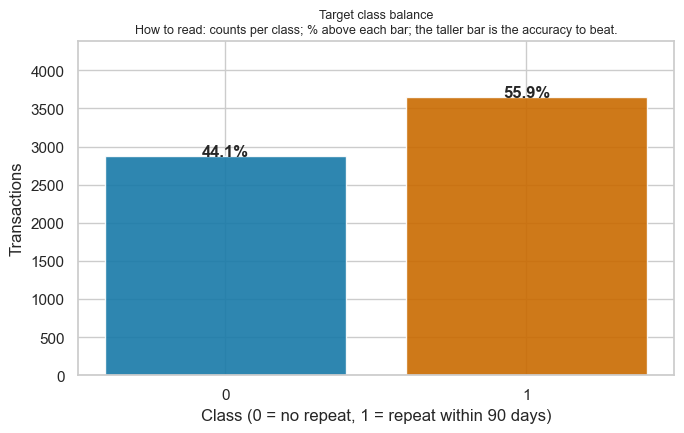

In [7]:
# CELL 7 - Target distribution, balance verdict, and the baseline to beat.
# Look at the target itself before looking at anything against it.
counts = train[TARGET].value_counts().sort_index()
share = train[TARGET].value_counts(normalize=True).sort_index()
baseline = share.max()
balance_ratio = share.min() / baseline

print("=== Target:", TARGET, "===")
print("  class    count    share")
for cls in counts.index:
    tag = "repeat buyer (positive)" if cls == 1 else "no repeat (negative)"
    print("  {}: {:>8,}  {:6.2f}%  - {}".format(cls, counts[cls], share[cls] * 100, tag))
print("\nMajority-class baseline accuracy: {:.2f}%  <- every model must beat this.".format(baseline * 100))
print("Minority/majority ratio: {:.2f}  (1.00 would be perfectly balanced).".format(balance_ratio))
if balance_ratio >= 0.5:
    print("Verdict: the classes are CLOSE TO BALANCED - an earlier draft called them 'imbalanced'")
    print("without checking, which the numbers above contradict. Accuracy is therefore not severely")
    print("misleading here; still, the Kaggle metric is F1 and the baseline sits only {:.1f} pp above".format((baseline - 0.5) * 100))
    print("a coin flip, so F1 (plus threshold tuning in NB04) remains the decision metric.")
else:
    print("Verdict: the classes are imbalanced; prefer F1 / balanced accuracy over plain accuracy.")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar([str(c) for c in counts.index], counts.values, color=[PLOT_BLUE, PLOT_ORANGE], alpha=0.9)
# Headroom so the bar labels never collide with the title.
ax.set_ylim(0, counts.values.max() * 1.20)
ax.set_title("Target class balance")
ax.set_xlabel("Class (0 = no repeat, 1 = repeat within 90 days)")
ax.set_ylabel("Transactions")
# Counts live in the printed table above; the figure adds only the share, so the two
# outputs complement each other instead of repeating the same numbers.
for i, v in enumerate(counts.values):
    ax.text(i, v, "{:.1f}%".format(share.values[i] * 100), ha="center", fontsize=12, fontweight="bold")
guide(ax, "How to read: counts per class; % above each bar; the taller bar is the accuracy to beat.")
plt.savefig(FIG_DIR / "nb01_01_target_balance.png", dpi=200)
plt.tight_layout()
plt.show()

### Cell 8 - Missing data
**Purpose.** Measure missingness on the column axis and the row axis, and separate structural nulls.
**Method.** Train and test compared side by side; then rows counted by how many cells are missing;
then the rows where every transaction field is null at once; then `clientes`.
**Look at.** The 65 structurally empty train rows (dropped in Notebook 02) and the joint pattern:
missing recency coincides with first-time buyers, so those nulls are information.

In [8]:
# CELL 8 - Missing data: column axis, row axis, and structural nulls.
miss = pd.DataFrame({
    "train_n": train.isna().sum(),
    "train_pct": train.isna().sum() / len(train) * 100,
    "test_n": test.isna().sum(),
    "test_pct": test.isna().sum() / len(test) * 100,
})
miss = miss[(miss["train_n"] > 0) | (miss["test_n"] > 0)].sort_values("train_pct", ascending=False)
miss.insert(0, "label", [clean_label(c) for c in miss.index])
print("=== Columns with missing values ===")
print(miss.round(2).to_string())

row_missing = train.isna().sum(axis=1)
print("\n=== Row-axis missingness (train): how many cells are missing per row ===")
print(row_missing.value_counts().sort_index().to_string())

# Structural anomaly: rows where every transaction field is null at once.
empty_rows = train[train["Total a Pagar"].isna()]
print("\n=== Structural nulls ===")
print("  train rows with ALL transaction fields missing:", len(empty_rows))
print("  test rows with 'Total a Pagar' missing        :", int(test["Total a Pagar"].isna().sum()))
kept = [clean_label(c) for c in empty_rows.columns if empty_rows[c].notna().sum() > 0]
print("  columns still populated in those train rows   :", kept)

# Joint pattern - new information, not a repeat of the column table above: how often the
# two recency signals fail TOGETHER in the same row.
both = int(((train["days_since_previous_purchase"].isna()) & (train["prior_purchase_count"] == 0)).sum())
print("\n=== Joint pattern ===")
print("  rows where recency is missing AND prior_purchase_count == 0:", both)
print("  -> consistent with first-time buyers having no history at all (missing by design).")

print("\n=== Clientes missingness (% of rows) ===")
cl_miss = clientes.isna().sum()
cl_miss = cl_miss[cl_miss > 0].sort_values(ascending=False) / len(clientes) * 100
cl_miss.index = [clean_label(c) for c in cl_miss.index]
print(cl_miss.round(1).to_string())
print("  customer_type 100% missing:", bool(clientes["customer_type"].isna().sum() == len(clientes)))

=== Columns with missing values ===
                                                          label  train_n  train_pct  test_n  test_pct
prior_std_gap_days                Prior Std Purchase Gap (Days)     1478      22.62    69.0      7.00
prior_mean_gap_days              Prior Mean Purchase Gap (Days)     1308      20.02    76.0      7.71
prior_std_purchase_value         Prior Std Purchase Value (EUR)     1113      17.03    46.0      4.67
prior_mean_purchase_value       Prior Mean Purchase Value (EUR)      862      13.19    52.0      5.27
days_since_previous_purchase       Days Since Previous Purchase      861      13.18    52.0      5.27
prior_max_purchase_value         Prior Max Purchase Value (EUR)      668      10.22    22.0      2.23
prior_min_purchase_value         Prior Min Purchase Value (EUR)      668      10.22    22.0      2.23
transport_method                               Transport Method      261       3.99    30.0      3.04
spend_365d                               Spend

### Cell 9 - Invalid values
**Purpose.** Find numbers that are present but cannot be true - a different problem from missing data.
**Method.** Look for 1e9-scale placeholders and for negative values in quantities that cannot be negative.
**Look at.** The counts per column. The decision recorded here (convert to NaN plus a flag, never
clip) is executed in Notebook 02, Cell 5.

In [9]:
# CELL 9 - Invalid values: an invalid value is not always missing data.
# These are real numbers that cannot be true (software placeholders / logging errors).
print("=== 1e9 sentinel placeholders ===")
for c in ["prior_mean_purchase_value", "spend_365d"]:
    print("  {:46s}: train >1e8 = {:4d} | test >1e8 = {:3d} | train max = {:,.0f}".format(
        clean_label(c) + " [" + c + "]", int((train[c] > 1e8).sum()), int((test[c] > 1e8).sum()), train[c].max()))

print("\n=== Impossible negative values ===")
for c in ["Total a Pagar", "Total Bruto", "Total Liquido", "spend_365d",
          "days_since_previous_purchase", "prior_mean_gap_days"]:
    if c in train.columns:
        print("  {:46s}: train negatives = {:4d} | min = {:,.2f}".format(
            clean_label(c) + " [" + c + "]", int((train[c] < 0).sum()), train[c].min()))

print("\nDecision for Notebook 02: sentinels (>= 1e8) and impossible negatives become NaN plus a")
print("missing-indicator flag. They are placeholders, so they must NOT be clipped to a number.")

=== 1e9 sentinel placeholders ===
  Prior Mean Purchase Value (EUR) [prior_mean_purchase_value]: train >1e8 =   16 | test >1e8 =   2 | train max = 1,000,000,000
  Spend (Past 365d, EUR) [spend_365d]           : train >1e8 =   15 | test >1e8 =   2 | train max = 1,000,000,000

=== Impossible negative values ===
  Total Payable (EUR) [Total a Pagar]           : train negatives =    0 | min = 0.93
  Gross Total (EUR) [Total Bruto]               : train negatives =    0 | min = 0.83
  Net Total (EUR) [Total Liquido]               : train negatives =    0 | min = 0.76
  Spend (Past 365d, EUR) [spend_365d]           : train negatives =   15 | min = -159,115.18
  Days Since Previous Purchase [days_since_previous_purchase]: train negatives =   16 | min = -4.00
  Prior Mean Purchase Gap (Days) [prior_mean_gap_days]: train negatives =   16 | min = -4.00

Decision for Notebook 02: sentinels (>= 1e8) and impossible negatives become NaN plus a
missing-indicator flag. They are placeholders, so they m

### Cell 10 - Numeric distributions, every feature
**Purpose.** Describe spread, skew, zero-inflation and missingness for all 29 numeric features.
**Method.** `describe()` plus skew, share of zeros and share of nulls; nothing is subset. The figure
standardises each column on the train mean and sd so all 29 share one comparable axis.
**Look at.** The degenerate boxes where Q1 = Q3 (zero-inflated columns) - the 1.5xIQR rule is
unreliable exactly there.

=== Numeric feature summary (train) - all 29 features ===
                                                          label    count         mean           std         min      25%      50%       75%              max  pct_missing  skew  pct_zeros
Total a Pagar                               Total Payable (EUR) 6,469.00       925.56      1,335.00        0.93   188.92   476.74  1,087.67        22,297.21         0.99  4.21       0.00
Total Bruto                                   Gross Total (EUR) 6,469.00       886.15      1,327.64        0.83   175.74   445.74  1,036.70        21,578.28         0.99  4.31       0.00
Total Liquido                                   Net Total (EUR) 6,469.00       773.34      1,136.36        0.76   154.38   389.91    903.37        18,127.81         0.99  4.15       0.00
Total Imp_                                      Tax Total (EUR) 6,469.00       152.22        225.26        0.00    29.93    79.74    184.84         4,169.40         0.99  4.84       3.26
Total P

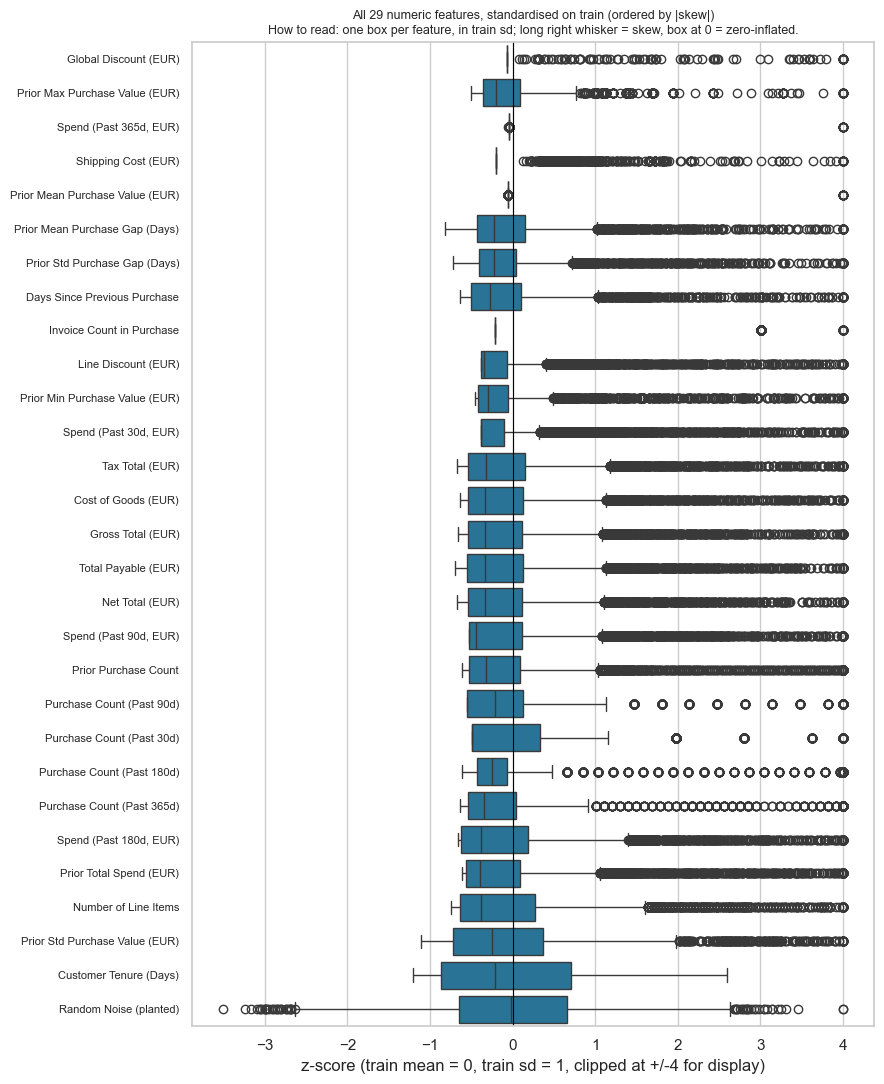

In [10]:
# CELL 10 - Numeric distributions for EVERY numeric feature (no subset, no ranking).
desc = train[feature_numeric].describe().T
desc["pct_missing"] = train[feature_numeric].isna().sum() / len(train) * 100
desc["skew"] = train[feature_numeric].skew()
desc["pct_zeros"] = (train[feature_numeric] == 0).sum() / len(train) * 100
desc.insert(0, "label", [clean_label(c) for c in desc.index])
print("=== Numeric feature summary (train) - all {} features ===".format(len(feature_numeric)))
# Plain decimal output: the default scientific notation on the mixed-scale columns is unreadable.
print(desc.to_string(float_format=lambda v: "{:,.2f}".format(v)))

skewed = desc.index[desc["skew"].abs() > 1.5].tolist()
zero_heavy = desc.index[desc["pct_zeros"] > 60].tolist()
print("\nHighly skewed (|skew| > 1.5) -> log1p candidates in NB02:")
print("  " + (", ".join(clean_label(c) for c in skewed) if skewed else "none"))
print("Zero-inflated (> 60% zeros) -> the 1.5xIQR boxplot rule is unreliable here:")
print("  " + (", ".join(clean_label(c) for c in zero_heavy) if zero_heavy else "none"))

# One figure that shows the shape of every feature at once. Each column is standardised with
# the TRAIN mean and sd so all 29 share one comparable axis (display only - NB02 fits its own
# scaler on train). Box = IQR, whiskers = 1.5xIQR, dots = beyond the fence.
mu = train[feature_numeric].mean()
sd = train[feature_numeric].std()
# Clipped at +/-4 for display: a few zero-inflated columns produce z-scores in the tens, which
# would squash every box against the axis. The exact statistics are in the table above.
z_train = ((train[feature_numeric] - mu) / sd).clip(-4, 4)
z_long = pd.melt(z_train, var_name="feature", value_name="z_score")
z_long["label"] = [clean_label(f) for f in z_long["feature"]]
order = [clean_label(c) for c in desc["skew"].abs().sort_values(ascending=False).index.tolist()]
z_long = z_long.assign(_o=[order.index(l) for l in z_long["label"]]).sort_values("_o")

fig, ax = plt.subplots(figsize=(9, 11))
sns.boxplot(data=z_long, y="label", x="z_score", orient="h", color=PLOT_BLUE, ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("All {} numeric features, standardised on train (ordered by |skew|)".format(len(feature_numeric)))
ax.set_xlabel("z-score (train mean = 0, train sd = 1, clipped at +/-4 for display)")
ax.set_ylabel("")
plt.setp(ax.get_yticklabels(), fontsize=8)
guide(ax, "How to read: one box per feature, in train sd; long right whisker = skew, box at 0 = zero-inflated.")
plt.savefig(FIG_DIR / "nb01_02_numeric_boxplots.png", dpi=200)
plt.tight_layout()
plt.show()

### Cell 11 - Histograms and outlier fences
**Purpose.** Show the shape of every numeric feature and quantify what the IQR rule would call extreme.
**Method.** One panel per feature, six per figure purely for readability; values at or above 1e8 are
excluded so a placeholder cannot flatten an axis. Fences are computed on the valid range.
**Look at.** The reading-guide panel in the last slot, and the share outside the fence per column.

=== All 29 histograms in ONE figure ===
Panels exclude values >= 100,000,000 (Cell 9 placeholders); the few impossible negatives
stay visible as a thin left tail - that tail is what NB02 turns into NaN + an indicator.


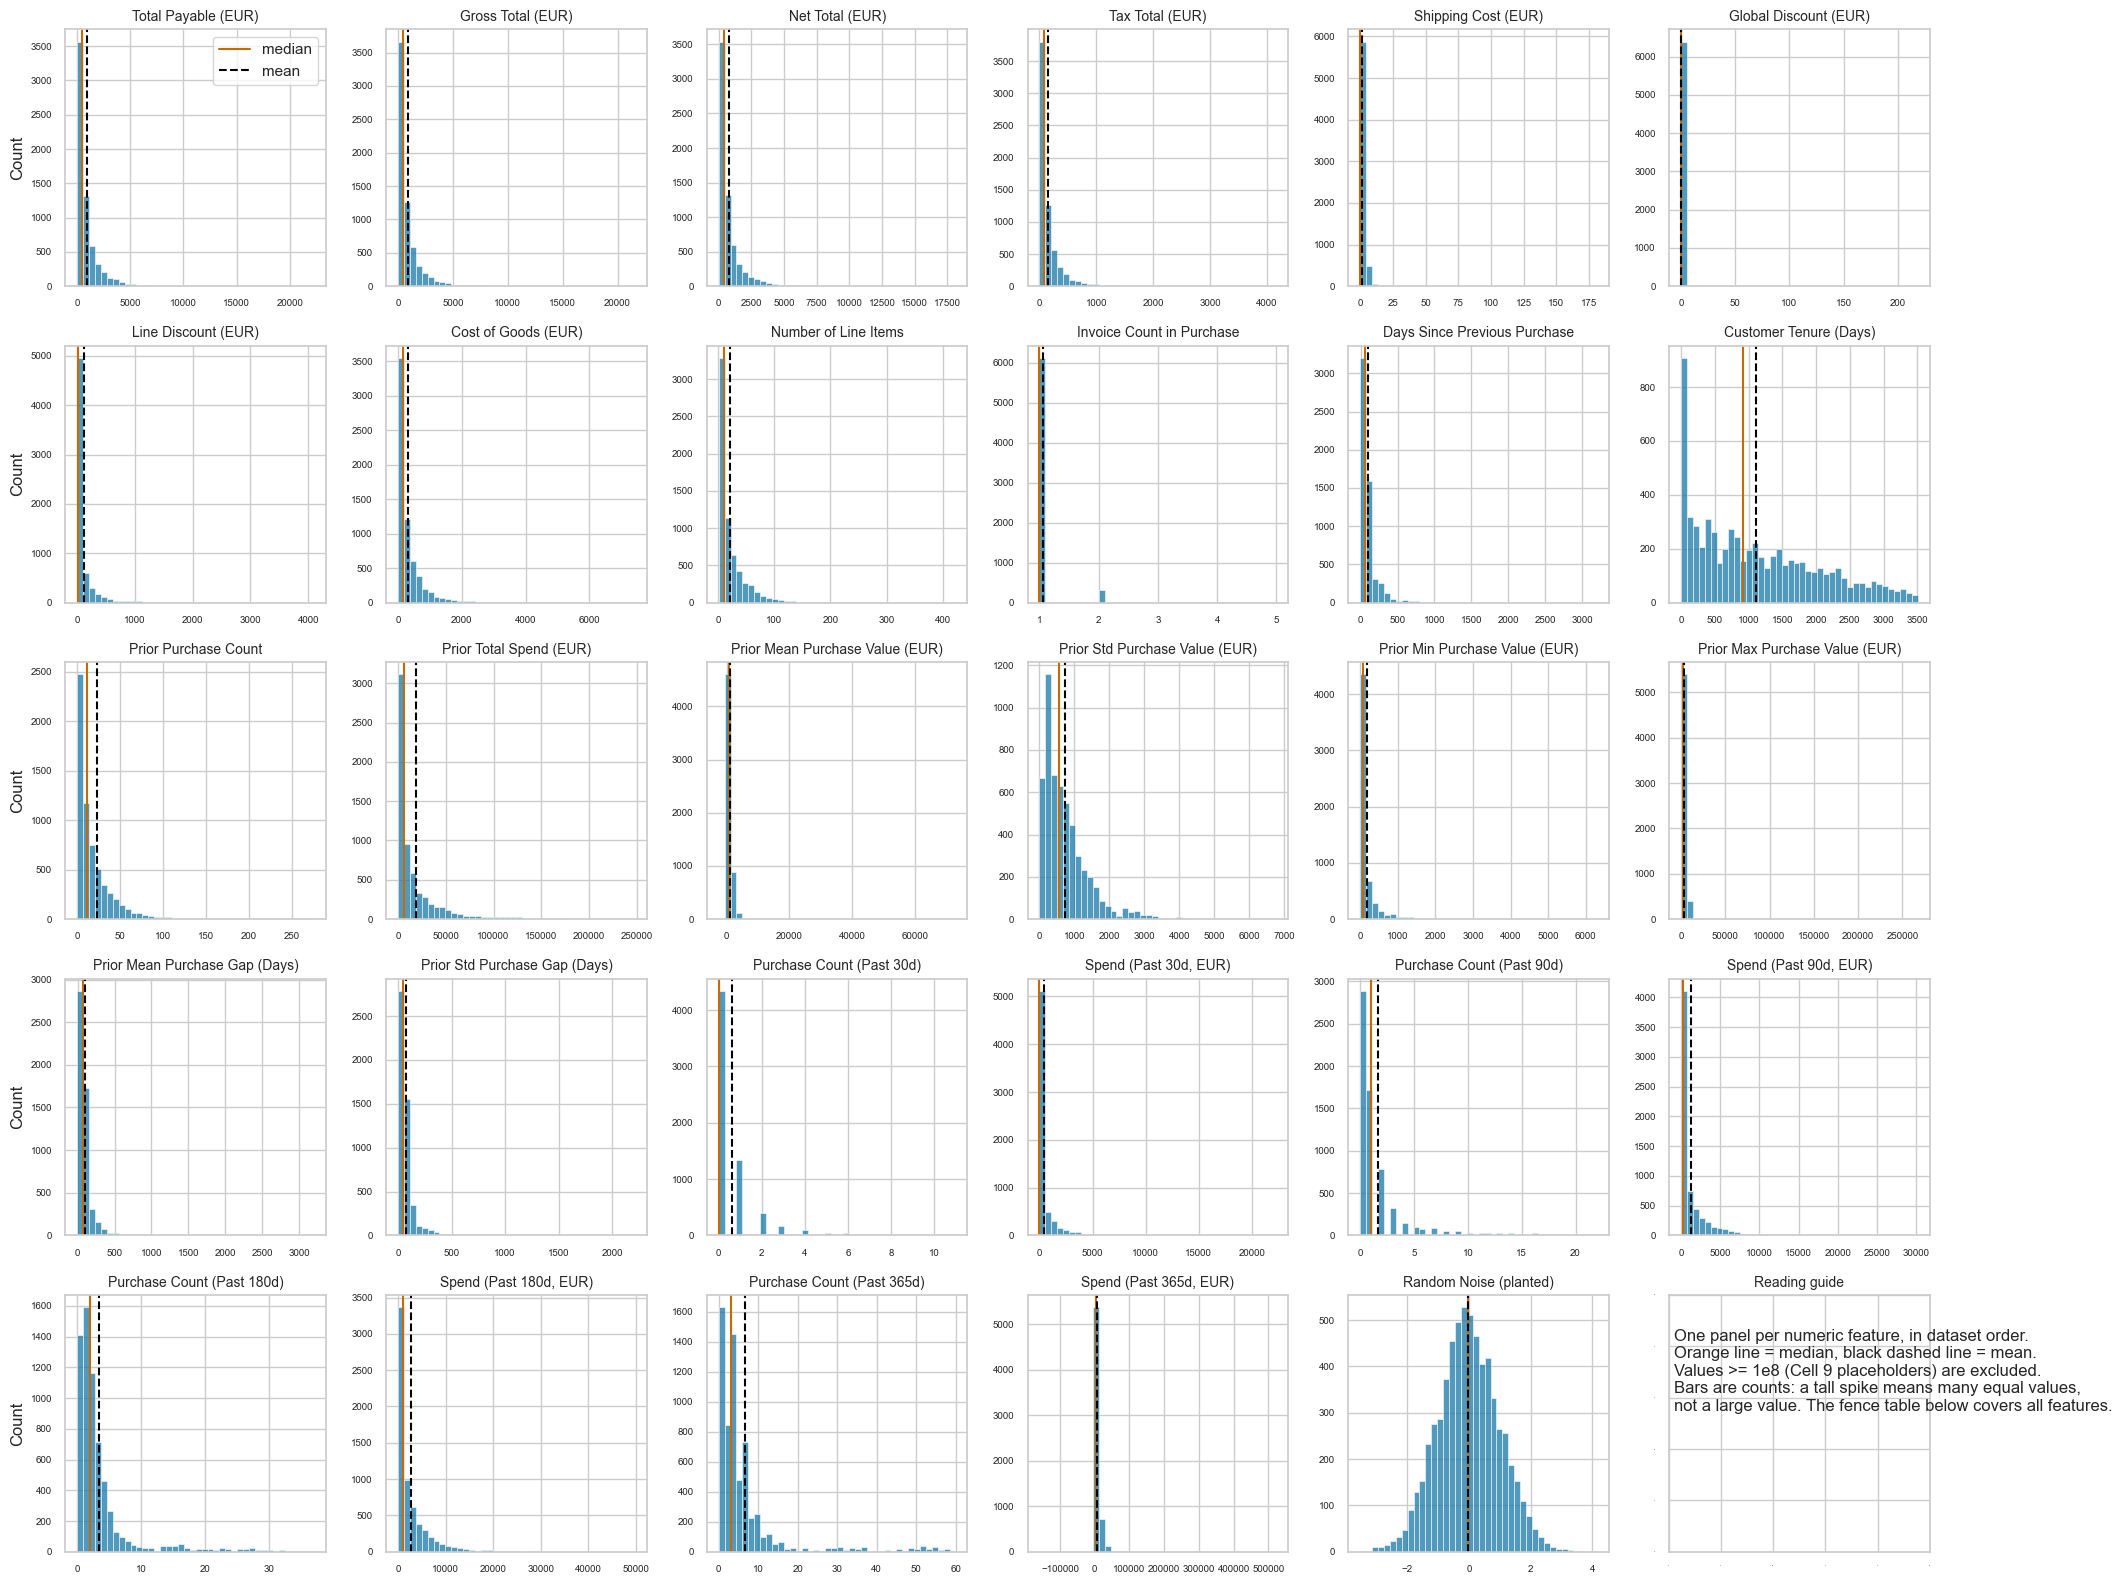


=== IQR outlier fences (1.5 x IQR) on valid values - ALL features, worst first ===
                          label                        feature      q1       q3  fence_low  fence_high  outside_n  outside_pct
          Spend (Past 30d, EUR)                      spend_30d     0.0    338.2     -507.4       845.6       1060         16.4
            Shipping Cost (EUR)                   Total Portes     0.0      0.0        0.0         0.0       1053         16.3
            Line Discount (EUR)              Total Desc_ Linha     0.0     92.3     -138.4       230.7        822         12.7
 Prior Min Purchase Value (EUR)       prior_min_purchase_value    15.4    162.6     -205.3       383.4        671         11.4
     Purchase Count (Past 180d)            purchase_count_180d     1.0      3.0       -2.0         6.0        737         11.4
          Spend (Past 90d, EUR)                      spend_90d     0.0  1,514.6   -2,271.8     3,786.4        661         10.2
        Prior Total Spend (

In [11]:
# CELL 11 - Histograms and outlier fences for ALL numeric features.
# Nothing is selected here: every numeric feature gets a panel. The panels are split across
# figures purely so each one stays readable - the split is mechanical (6 per figure), not a
# judgement about which features matter.
# Cell 9 found 1e9 placeholders, so shape statistics ignore values >= 1e8: one placeholder
# would flatten the axis and inflate the upper fence into meaninglessness.
VALID_MAX = 1e8


def valid_values(col):
    s = train[col].dropna()
    return s[s < VALID_MAX]


print("=== All {} histograms in ONE figure ===".format(len(feature_numeric)))
print("Panels exclude values >= {:,.0f} (Cell 9 placeholders); the few impossible negatives".format(VALID_MAX))
print("stay visible as a thin left tail - that tail is what NB02 turns into NaN + an indicator.")

N_COLS = 6
n_rows = -(-len(feature_numeric) // N_COLS)
fig, axes = plt.subplots(n_rows, N_COLS, figsize=(3.6 * N_COLS, 3.2 * n_rows))
for k, (ax, col) in enumerate(zip(axes.ravel(), feature_numeric)):
    s = valid_values(col)
    sns.histplot(s, bins=40, color=PLOT_BLUE, ax=ax)
    ax.axvline(s.median(), color=PLOT_ORANGE, linestyle="-", label="median")
    ax.axvline(s.mean(), color="black", linestyle="--", label="mean")
    ax.set_title(clean_label(col), fontsize=10)
    ax.set_xlabel("")  # the title names the panel; seaborn would print the raw column name
    ax.set_ylabel("Count" if k % N_COLS == 0 else "")  # one y-label per row, not 29 copies
    ax.tick_params(axis="x", labelsize=7)
    ax.tick_params(axis="y", labelsize=7)
    if k == 0:
        ax.legend(loc="upper right")  # the spike is on the left, so this corner stays free

# 29 is prime, so a rectangular grid always leaves one slot free: it carries the reading
# guide instead of an empty box.
guide_ax = axes.ravel()[len(feature_numeric)]
guide_ax.set_title("Reading guide", fontsize=10)
guide_ax.text(0.02, 0.55, "One panel per numeric feature, in dataset order.\n"
                       "Orange line = median, black dashed line = mean.\n"
                       "Values >= 1e8 (Cell 9 placeholders) are excluded.\n"
                       "Bars are counts: a tall spike means many equal values,\n"
                       "not a large value. The fence table below covers all features.")
guide_ax.tick_params(axis="both", labelsize=0)
plt.savefig(FIG_DIR / "nb01_03_histograms_all.png", dpi=200)
plt.tight_layout()
plt.show()

fence_rows = []
for col in feature_numeric:
    s = valid_values(col)
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo = q1 - 1.5 * iqr
    hi = q3 + 1.5 * iqr
    outside = int(((s < lo) | (s > hi)).sum())
    fence_rows.append({"label": clean_label(col), "feature": col, "q1": q1, "q3": q3,
                       "fence_low": lo, "fence_high": hi, "outside_n": outside,
                       "outside_pct": outside / len(s) * 100})
fences = pd.DataFrame(fence_rows).sort_values("outside_pct", ascending=False)
print("\n=== IQR outlier fences (1.5 x IQR) on valid values - ALL features, worst first ===")
print(fences.to_string(index=False, float_format=lambda v: "{:,.1f}".format(v)))
print("Note: the 1.5xIQR rule is descriptive only. Where Q1 = Q3 (zero-inflated or near-constant")
print("columns) the fence collapses, so the outside share is an artefact rather than an outlier")
print("count; NB02 handles extremes with log1p + clipping instead of dropping rows.")

### Cell 12 - Categorical levels
**Purpose.** List every level of every categorical column.
**Method.** Counting nulls cannot reveal a typo or a placeholder string such as `"unknown"`, so the
levels themselves are printed with their support.
**Look at.** `transport_method` has 80 levels - that is what forces the rare-level grouping in
Notebook 02.

In [12]:
# CELL 12 - Categorical features: EVERY level listed, nothing truncated.
# The course recipe is to list the levels rather than only count them: typos and placeholder
# strings ("unknown", "-", "n/a") are invisible to a null count but obvious in a listing.
PLACEHOLDERS = {"?", "unknown", "n/a", "na", "none", "null", "nan", "-", ""}
for col in categorical_cols:
    vc = train[col].value_counts()
    print("\n=== {} [raw: {}] ===".format(clean_label(col), col))
    print("  levels: {:3d} | rows with a value: {:,} | missing: {:,}".format(
        train[col].nunique(), int(vc.sum()), int(train[col].isna().sum())))
    listing = pd.DataFrame({"level": vc.index.astype(str), "n": vc.values,
                            "pct_of_rows": vc.values / len(train) * 100})
    print(listing.to_string(index=False, float_format=lambda v: "{:.2f}".format(v)))
    ph = sorted({str(x).strip().lower() for x in vc.index
                 if str(x).strip().lower() in PLACEHOLDERS})
    if ph:
        print("  placeholder-like levels detected:", ph)


=== Payment Method [raw: payment_type] ===
  levels:   9 | rows with a value: 6,274 | missing: 260
                    level    n  pct_of_rows
 Maybe Tomorrow Payment 7 4565        69.87
Maybe Tomorrow Payment 12  991        15.17
 Maybe Tomorrow Payment 9  502         7.68
Maybe Tomorrow Payment 10  134         2.05
 Maybe Tomorrow Payment 8   40         0.61
 Maybe Tomorrow Payment 2   21         0.32
 Maybe Tomorrow Payment 4    9         0.14
Maybe Tomorrow Payment 11    8         0.12
 Maybe Tomorrow Payment 3    4         0.06

=== Salesperson Code [raw: salesperson] ===
  levels:   9 | rows with a value: 6,275 | missing: 259
           level    n  pct_of_rows
VLOOKUP Master 1 4054        62.04
VLOOKUP Master 4 1461        22.36
VLOOKUP Master 9  384         5.88
VLOOKUP Master 7  201         3.08
VLOOKUP Master 2  123         1.88
VLOOKUP Master 3   30         0.46
VLOOKUP Master 6   12         0.18
VLOOKUP Master 5    7         0.11
VLOOKUP Master 8    3         0.05

=== Comm

### Cell 13 - Numeric signal against the target
**Purpose.** Measure how much each numeric feature alone says about the target.
**Method.** Point-biserial correlation with its p-value. For a 0/1 target it equals the Pearson r, so
only one column is shown. Spearman and mutual information are concept-only in this course and are
not used.
**Look at.** The purchase-count family at the top (|r| around 0.4) and `random_noise` at the bottom.

=== Numeric association with target - all 29 features (point-biserial r) ===
                          label                        feature       r  abs_r  p_value  n_used
     Purchase Count (Past 365d)            purchase_count_365d  0.3403 0.3403   0.0000    6469
     Purchase Count (Past 180d)            purchase_count_180d  0.3342 0.3342   0.0000    6469
      Purchase Count (Past 90d)             purchase_count_90d  0.3279 0.3279   0.0000    6469
         Spend (Past 180d, EUR)                     spend_180d  0.3010 0.3010   0.0000    6469
           Prior Purchase Count           prior_purchase_count  0.2988 0.2988   0.0000    6469
          Spend (Past 90d, EUR)                      spend_90d  0.2689 0.2689   0.0000    6469
      Purchase Count (Past 30d)             purchase_count_30d  0.2633 0.2633   0.0000    6469
        Prior Total Spend (EUR)              prior_total_spend  0.2619 0.2619   0.0000    6469
 Prior Mean Purchase Gap (Days)            prior_mean_gap_days -0.23

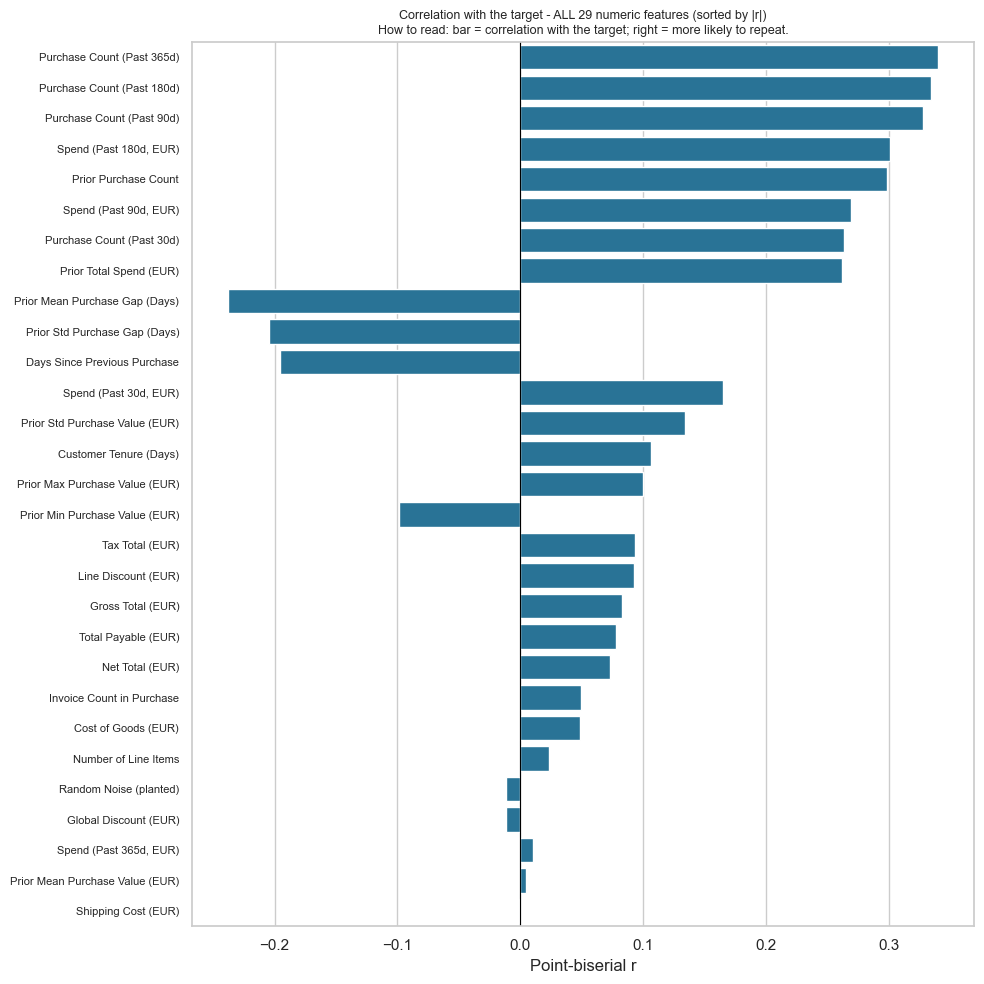

In [13]:
# CELL 13 - Numeric association with the target for EVERY numeric feature.
# Taught measure: point-biserial correlation (numeric vs binary target) with its p-value.
# For a 0/1 target the point-biserial r IS the Pearson r, so printing both would show the
# same number twice; one column is enough. Spearman / mutual info are concept-only here.
rows = []
for col in feature_numeric:
    valid = train[[col, TARGET]].dropna()
    if valid[col].nunique() < 2:
        continue
    pb = pointbiserialr(valid[TARGET], valid[col])
    rows.append({"feature": col, "r": pb.statistic, "abs_r": abs(pb.statistic),
                 "p_value": pb.pvalue, "n_used": len(valid)})

assoc = pd.DataFrame(rows).sort_values("abs_r", ascending=False).reset_index(drop=True)
assoc.insert(0, "label", [clean_label(f) for f in assoc["feature"]])
print("=== Numeric association with target - all {} features (point-biserial r) ===".format(len(assoc)))
print(assoc.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 10))
sns.barplot(data=assoc, y="label", x="r", orient="h", color=PLOT_BLUE, ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Correlation with the target - ALL {} numeric features (sorted by |r|)".format(len(assoc)))
ax.set_xlabel("Point-biserial r")
ax.set_ylabel("")
plt.setp(ax.get_yticklabels(), fontsize=8)
guide(ax, "How to read: bar = correlation with the target; right = more likely to repeat.")
plt.savefig(FIG_DIR / "nb01_04_association_numeric.png", dpi=200)
plt.tight_layout()
plt.show()

### Cell 14 - Redundancy between predictors
**Purpose.** Find features that are the same information twice, which is what makes coefficients
unstable in a linear model.
**Method.** Full Pearson matrix over all numeric predictors, diagonal included as the reference,
diverging red(-) to green(+) scale, and annotations only where |r| is at least 0.30.
**Look at.** The blocks of near-1.0 among the monetary totals and among the count/spend windows,
and the 16 pairs at or above 0.80 that Notebook 03 prunes.

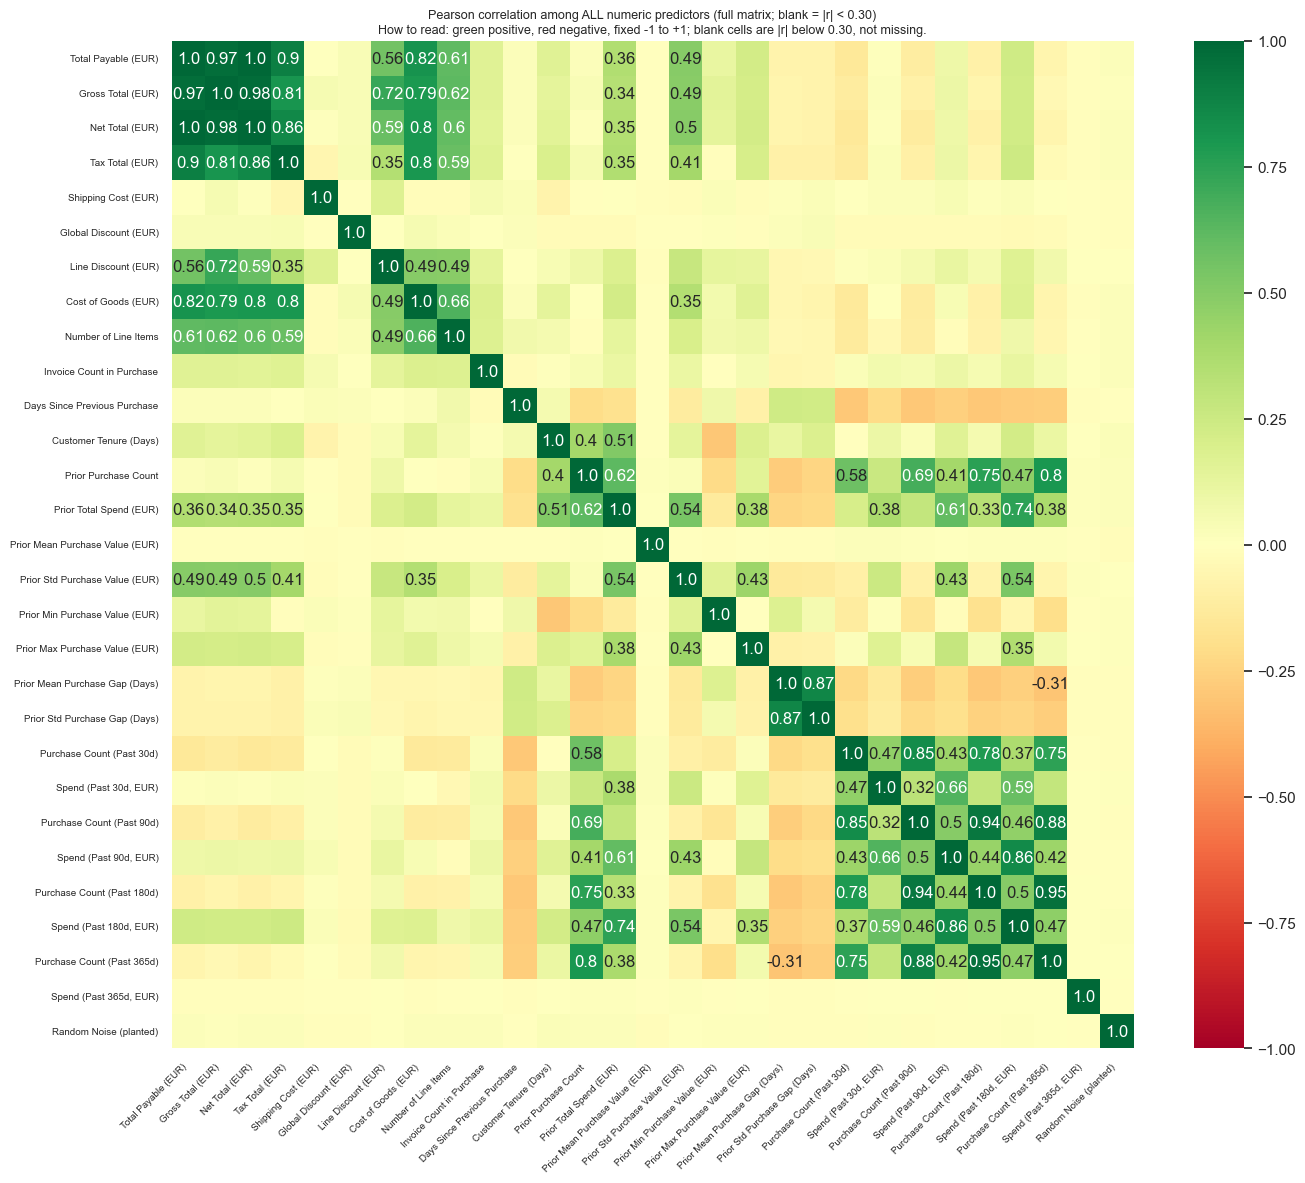

=== Predictor pairs with |Pearson r| >= 0.80: 16 ===
                       label_1                       label_2            feature_1           feature_2  pearson_r
           Total Payable (EUR)               Net Total (EUR)        Total a Pagar       Total Liquido      0.996
             Gross Total (EUR)               Net Total (EUR)          Total Bruto       Total Liquido      0.984
           Total Payable (EUR)             Gross Total (EUR)        Total a Pagar         Total Bruto      0.975
    Purchase Count (Past 180d)    Purchase Count (Past 365d)  purchase_count_180d purchase_count_365d      0.954
     Purchase Count (Past 90d)    Purchase Count (Past 180d)   purchase_count_90d purchase_count_180d      0.935
           Total Payable (EUR)               Tax Total (EUR)        Total a Pagar          Total Imp_      0.901
     Purchase Count (Past 90d)    Purchase Count (Past 365d)   purchase_count_90d purchase_count_365d      0.883
Prior Mean Purchase Gap (Days) Prior Std Pu

In [14]:
# CELL 14 - Redundancy among predictors (multicollinearity).
# Correlated over ALL numeric predictors, not a top-k subset: ranking by target correlation
# first could hide collinearity between features that are individually weaker but redundant.
# Pairs with |r| >= 0.80 are pruned in NB03.
corr = train[feature_numeric].corr(numeric_only=True)

# Readability rules:
#  * the FULL square matrix is shown, diagonal included: r = 1.00 on the diagonal is the
#    reference that orients the reader and confirms the matrix is symmetric;
#  * diverging scale: strong negative = red, strong positive = green (vmin/vmax = -1/+1);
#  * annotate only |r| >= threshold, leaving weak cells blank so the eye goes straight to
#    the associations that matter instead of scanning a wall of numbers;
#  * axis ticks use the human-readable labels defined in Cell 5.
CORR_ANNOT_THRESH = 0.30
annot_txt = corr.round(2).astype(str)
annot_txt = annot_txt.mask(corr.abs() < CORR_ANNOT_THRESH, "")
corr_lbl = corr.copy()
corr_lbl.index = [clean_label(c) for c in corr_lbl.index]
corr_lbl.columns = [clean_label(c) for c in corr_lbl.columns]
annot_lbl = annot_txt.copy()
annot_lbl.index = corr_lbl.index
annot_lbl.columns = corr_lbl.columns

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr_lbl, annot=annot_lbl, fmt="", vmin=-1, vmax=1, cmap="RdYlGn", ax=ax)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", fontsize=7)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=7)
ax.set_title("Pearson correlation among ALL numeric predictors (full matrix; blank = |r| < {:.2f})".format(CORR_ANNOT_THRESH))
guide(ax, "How to read: green positive, red negative, fixed -1 to +1; blank cells are |r| below 0.30, not missing.")
plt.savefig(FIG_DIR / "nb01_05_correlation_heatmap.png", dpi=200)
plt.tight_layout()
plt.show()

cols = corr.columns.tolist()
pairs = []
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        v = corr.loc[a, b]
        if pd.notna(v) and abs(v) >= 0.80:
            pairs.append({"feature_1": a, "feature_2": b, "pearson_r": v})
pairs_df = pd.DataFrame(pairs, columns=["feature_1", "feature_2", "pearson_r"])
if len(pairs_df):
    pairs_df = pairs_df.sort_values("pearson_r", key=abs, ascending=False)
    pairs_df.insert(0, "label_1", [clean_label(c) for c in pairs_df["feature_1"]])
    pairs_df.insert(1, "label_2", [clean_label(c) for c in pairs_df["feature_2"]])
print("=== Predictor pairs with |Pearson r| >= 0.80: {} ===".format(len(pairs_df)))
print(pairs_df.round(3).to_string(index=False) if len(pairs_df) else "  none")

### Cell 15 - Categorical signal against the target
**Purpose.** Measure association for the categorical features and show where the rate actually moves.
**Method.** Cramer's V from `chi2_contingency` tables, then one panel per feature with the group size
`n` printed inside each bar.
**Look at.** A high rate on a tiny bar is noise: `Salesperson Code` tops out at 100% on 3 rows, while
`Payment Method` reaches 97% on 502.

=== Categorical association with target (Cramer's V) - all 6 features ===
             label          feature  levels  cramers_v
  Transport Method transport_method      80     0.2899
    Payment Method     payment_type       9     0.2376
  Salesperson Code      salesperson       9     0.2033
   Commercial Zone  commercial_zone       5     0.0638
Warehouse Location        warehouse       2     0.0266
   Document Series  document_series       3     0.0029


  Transport Method has 80 levels: the 12 most frequent are plotted, all 80 are listed in Cell 12


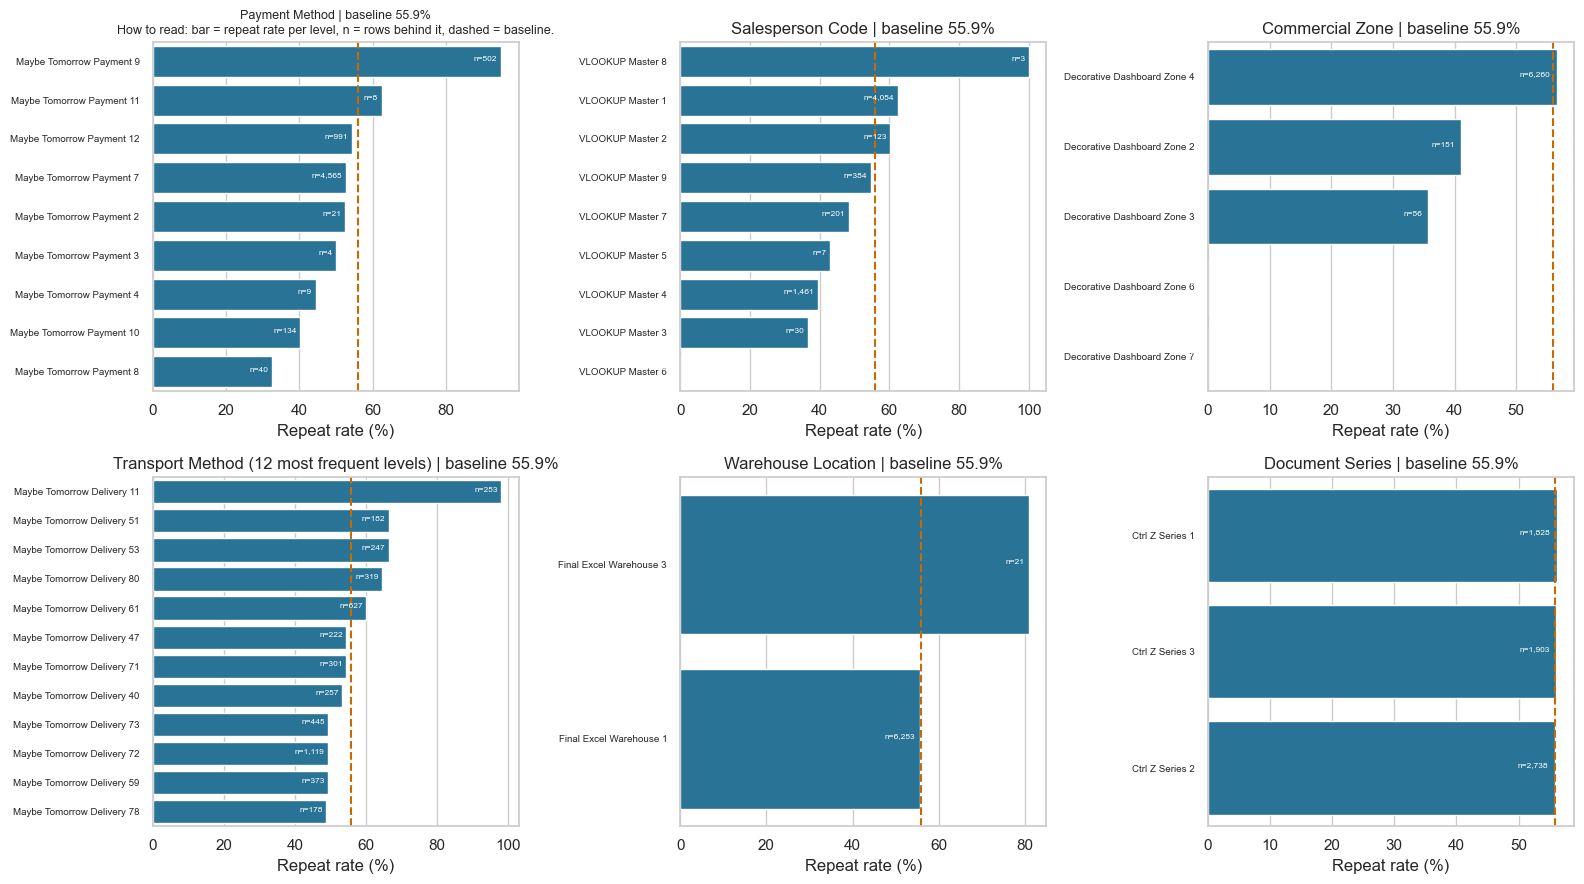

In [15]:
# CELL 15 - Categorical association with the target (Cramer's V) for EVERY categorical.
# Taught measures: chi2_contingency and association(method="cramer", correction=True).
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    if table.shape[0] < 2 or table.shape[1] < 2:
        return np.nan
    return association(table.values, method="cramer", correction=True)


cat_rows = []
for col in categorical_cols:
    valid = train[[col, TARGET]].dropna()
    cat_rows.append({"feature": col, "levels": int(train[col].nunique()),
                     "cramers_v": cramers_v(valid[col], valid[TARGET])})
cat_df = pd.DataFrame(cat_rows).sort_values("cramers_v", ascending=False).reset_index(drop=True)
cat_df.insert(0, "label", [clean_label(c) for c in cat_df["feature"]])
print("=== Categorical association with target (Cramer's V) - all {} features ===".format(len(cat_df)))
print(cat_df.round(4).to_string(index=False))

# Repeat rate by level, for every categorical feature. Horizontal bars because the level
# names are long, and each bar carries its group size n: a rate without its n can mislead.
base = train[TARGET].mean() * 100
PANEL_LEVEL_CAP = 12  # a panel with more bars than this stops being readable
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for k, (ax, col) in enumerate(zip(axes.ravel(), categorical_cols)):
    rate = train.groupby(col)[TARGET].mean() * 100
    nsup = train[col].value_counts()
    tbl = pd.DataFrame({"n": nsup, "rate_pct": rate}).dropna()
    capped = len(tbl) > PANEL_LEVEL_CAP
    if capped:
        tbl = tbl.sort_values("n", ascending=False).head(PANEL_LEVEL_CAP)
    tbl = tbl.sort_values("rate_pct", ascending=False)
    sns.barplot(x=tbl["rate_pct"].values, y=tbl.index.astype(str), orient="h", color=PLOT_BLUE, ax=ax)
    # Each bar carries its group size: a rate from a handful of rows is not evidence.
    for i, (r, n) in enumerate(zip(tbl["rate_pct"].values, tbl["n"].values)):
        ax.text(r - 1, i, "n={:,}".format(int(n)), ha="right", fontsize=6, color="white")
    ax.axvline(base, color=PLOT_ORANGE, linestyle="--")
    # The baseline value goes in the title, not in a legend: a legend box lands on top of the
    # longest bar in whichever corner it occupies.
    ax.set_title("{}{} | baseline {:.1f}%".format(
        clean_label(col),
        " ({} most frequent levels)".format(PANEL_LEVEL_CAP) if capped else "", base))
    ax.set_xlabel("Repeat rate (%)")
    ax.set_ylabel("")
    plt.setp(ax.get_yticklabels(), fontsize=7)
    if capped:
        print("  {} has {} levels: the {} most frequent are plotted, all {} are listed in Cell 12".format(
            clean_label(col), train[col].nunique(), PANEL_LEVEL_CAP, train[col].nunique()))
guide(axes.ravel()[0], "How to read: bar = repeat rate per level, n = rows behind it, dashed = baseline.")
plt.savefig(FIG_DIR / "nb01_06_categorical_rates.png", dpi=200)
plt.tight_layout()
plt.show()

### Cell 16 - Customer metadata
**Purpose.** Profile `clientes` and measure what the join can actually contribute.
**Method.** Coverage of the join key, then repeat rate by attribute restricted to levels with at least
100 rows, because a rate from a handful of rows is not evidence.
**Look at.** The largest trusted deviation per attribute: commercial region reaches 38.5 points away
from the baseline, which is why `clientes` is kept as a candidate rather than dismissed.

=== clientes profile ===
  rows / unique customer_id : 1143 / 1143
  registration year range   : 2015 - 2026

  attribute cardinality (nunique):
                                     label  n_unique
customer_id                    Customer ID      1143
country_or_region         Country / Region        11
commercial_region        Commercial Region        37
island                              Island        10
municipality                  Municipality       183
city                                  City       417
postal_area                    Postal Area       271
postal_code                    Postal Code       828
street                              Street       511
address                            Address      1120
customer_type                Customer Type         0
company_name                  Company Name      1141
customer_since_year  Customer Since (Year)        12

=== Join coverage on customer_id ===
  train rows matched in clientes : 100.0%
  test rows matched in clientes  

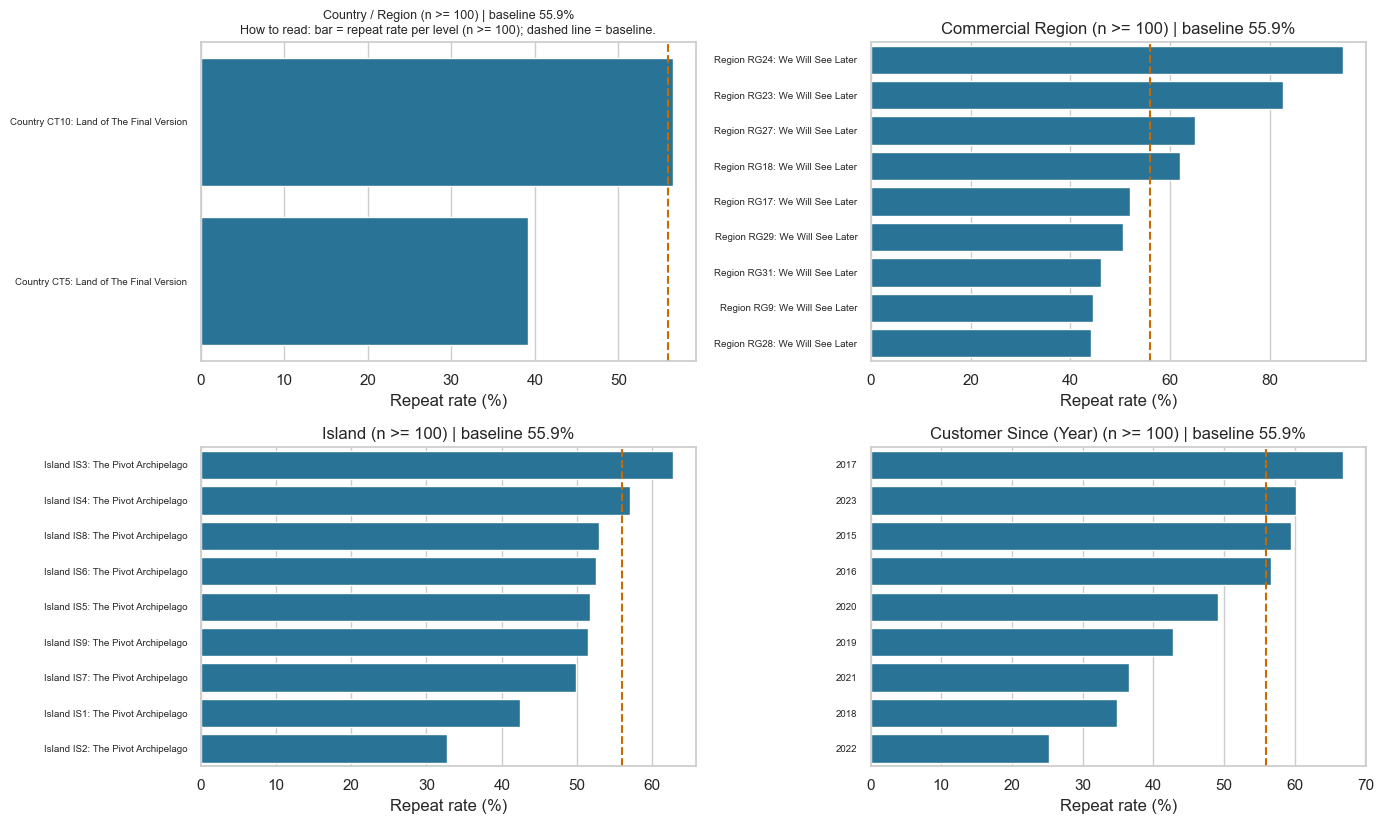

  Country / Region            : most deviating trusted level = Country CT5: Land of The Final Version | n = 194 | rate = 39.2% | dev = 16.7 pp
  Commercial Region           : most deviating trusted level = Region RG24: We Will See Later | n = 235 | rate = 94.5% | dev = 38.5 pp
  Island                      : most deviating trusted level = Island IS2: The Pivot Archipelago | n = 107 | rate = 32.7% | dev = 23.2 pp
  Customer Since (Year)       : most deviating trusted level = 2022 | n = 111 | rate = 25.2% | dev = 30.7 pp

-> clientes attributes DO move the target, so the earlier claim that clientes 'adds little
   beyond customer_id' was an unverified assumption. NB04 settles keep/drop by ablation.


In [16]:
# CELL 16 - Customer metadata (clientes): profile, join coverage, and every attribute.
print("=== clientes profile ===")
print("  rows / unique customer_id :", len(clientes), "/", clientes["customer_id"].nunique())
print("  registration year range   :", int(clientes["customer_since_year"].min()), "-",
      int(clientes["customer_since_year"].max()))
print("\n  attribute cardinality (nunique):")
card = clientes.nunique().to_frame("n_unique")
card.insert(0, "label", [clean_label(c) for c in card.index])
print(card.to_string())

train_cov = train["customer_id"].isin(clientes["customer_id"]).sum() / len(train) * 100
test_cov = test["customer_id"].isin(clientes["customer_id"]).sum() / len(test) * 100
overlap = train.loc[train["customer_id"].isin(test["customer_id"]), "customer_id"].nunique()
print("\n=== Join coverage on customer_id ===")
print("  train rows matched in clientes : {:.1f}%".format(train_cov))
print("  test rows matched in clientes  : {:.1f}%".format(test_cov))
print("  customers in BOTH train and test:", overlap)

# Exploratory left join for insight only; NB02 decides whether clientes is kept (ablation).
train_merged = train.set_index("customer_id").join(clientes.set_index("customer_id")).reset_index()
base = train[TARGET].mean() * 100
MIN_GROUP = 100  # a rate computed on fewer rows than this is noise, not evidence
MAX_LEVELS = 40  # above this a column is an identifier or free text, not a categorical feature


def rate_table(col):
    rate = train_merged.groupby(col)[TARGET].mean() * 100
    tbl = pd.DataFrame({"n": train_merged[col].value_counts(), "rate_pct": rate})
    tbl["dev_pp"] = (tbl["rate_pct"] - base).abs()
    return tbl[tbl["n"] >= MIN_GROUP]


meta_cols = [c for c in clientes.columns
             if c != "customer_id" and clientes[c].notna().any()
             and clientes[c].nunique() <= MAX_LEVELS]
skipped = [c for c in clientes.columns if c != "customer_id" and c not in meta_cols]
print("\n=== Attributes analysed (rule: at least one value present and <= {} distinct levels) ===".format(MAX_LEVELS))
print("  analysed :", [clean_label(c) for c in meta_cols])
print("  excluded :", [clean_label(c) for c in skipped])
print("  -> excluded columns are free text / near-unique identifiers (city, street, address,")
print("     postal_code, company_name, ...) or fully empty (customer_type); they are not")
print("     model inputs, and NB02 treats them as identifiers, not as features.")

tables = {}
for col in meta_cols:
    tbl = rate_table(col)
    if not len(tbl):
        print("\n=== {} [raw: {}] === no level reaches n >= {}".format(clean_label(col), col, MIN_GROUP))
        continue
    tables[col] = tbl
    print("\n=== {} [raw: {}] ===".format(clean_label(col), col))
    print("  {} of {} levels have n >= {}; those levels cover {:.1f}% of joined rows".format(
        len(tbl), int(train_merged[col].nunique()), MIN_GROUP, tbl["n"].sum() / len(train_merged) * 100))
    print(tbl.sort_values("rate_pct", ascending=False).round(1).to_string())

show_cols = list(tables)
n_panels = len(show_cols)
n_cols = 2 if n_panels > 2 else max(n_panels, 1)
n_rows = -(-n_panels // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 4.2 * n_rows))
axes = list(axes.ravel()) if n_panels > 1 else [axes]
for ax, col in zip(axes, show_cols):
    tbl = tables[col].sort_values("rate_pct", ascending=False)
    sns.barplot(x=tbl["rate_pct"].values, y=tbl.index.astype(str), orient="h", color=PLOT_BLUE, ax=ax)
    ax.axvline(base, color=PLOT_ORANGE, linestyle="--")
    ax.set_title("{} (n >= {}) | baseline {:.1f}%".format(clean_label(col), MIN_GROUP, base))
    ax.set_xlabel("Repeat rate (%)")
    ax.set_ylabel("")
    plt.setp(ax.get_yticklabels(), fontsize=7)
guide(axes[0], "How to read: bar = repeat rate per level (n >= 100); dashed line = baseline.")
plt.savefig(FIG_DIR / "nb01_07_clientes_attributes.png", dpi=200)
plt.tight_layout()
plt.show()

# Evidence for the keep/drop decision instead of an assumption: the most deviating trusted level.
for col, tbl in tables.items():
    top_lvl = tbl["dev_pp"].idxmax()
    print("  {:28s}: most deviating trusted level = {} | n = {} | rate = {:.1f}% | dev = {:.1f} pp".format(
        clean_label(col), top_lvl, int(tbl.loc[top_lvl, "n"]), tbl.loc[top_lvl, "rate_pct"],
        tbl.loc[top_lvl, "dev_pp"]))
print("\n-> clientes attributes DO move the target, so the earlier claim that clientes 'adds little")
print("   beyond customer_id' was an unverified assumption. NB04 settles keep/drop by ablation.")

### Cell 17 - Train versus test
**Purpose.** Test the assumption that the two sets come from the same population.
**Method.** `ks_2samp` is not taught, so the comparison is descriptive: mean gap expressed in train
standard deviations (percentage differences explode when a train mean is near zero), one paired
boxplot for all features, and overlaid histograms for the two largest gaps.
**Look at.** `customer_tenure_days`: the test rows sit clearly further right. This single finding is
why Notebook 04 reports a chronological validation.

=== Train -> test shift for ALL numeric features (sorted by |std_diff|) ===
                                                          label    train_mean     test_mean      train_std  mean_diff_pct  std_diff  abs_std_diff
customer_tenure_days                     Customer Tenure (Days)     1,111.384     2,448.730        923.191        120.332     1.449         1.449
prior_total_spend                       Prior Total Spend (EUR)    18,908.349    49,431.583     31,130.865        161.427     0.980         0.980
Total Desc_ Linha                           Line Discount (EUR)       112.466       261.866        289.986        132.839     0.515         0.515
prior_purchase_count                       Prior Purchase Count        23.458        42.909         38.345         82.918     0.507         0.507
prior_std_purchase_value         Prior Std Purchase Value (EUR)       737.470     1,032.082        666.262         39.949     0.442         0.442
Total Bruto                                   Gr

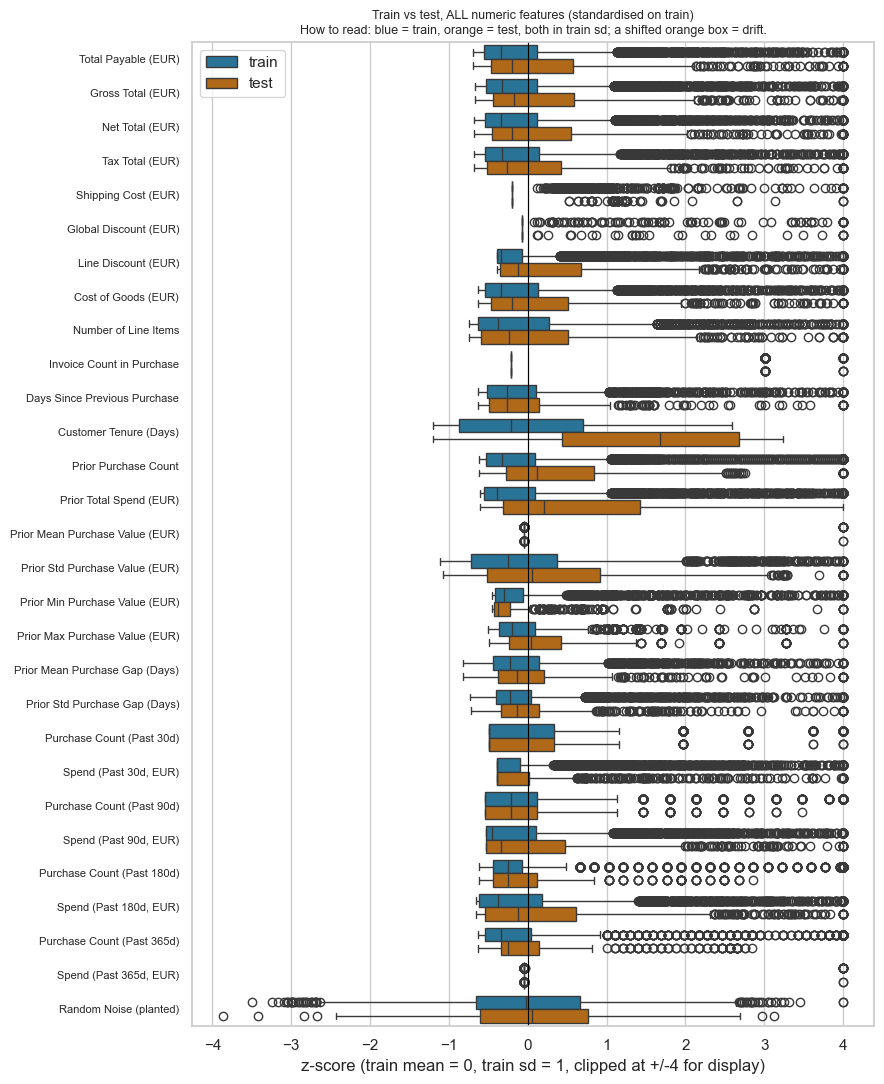


Overlaid histograms for the two largest |std_diff|: ['Customer Tenure (Days)', 'Prior Total Spend (EUR)']
Note: test holds ~6.6x fewer rows than train, so compare distribution SHAPES, not heights.


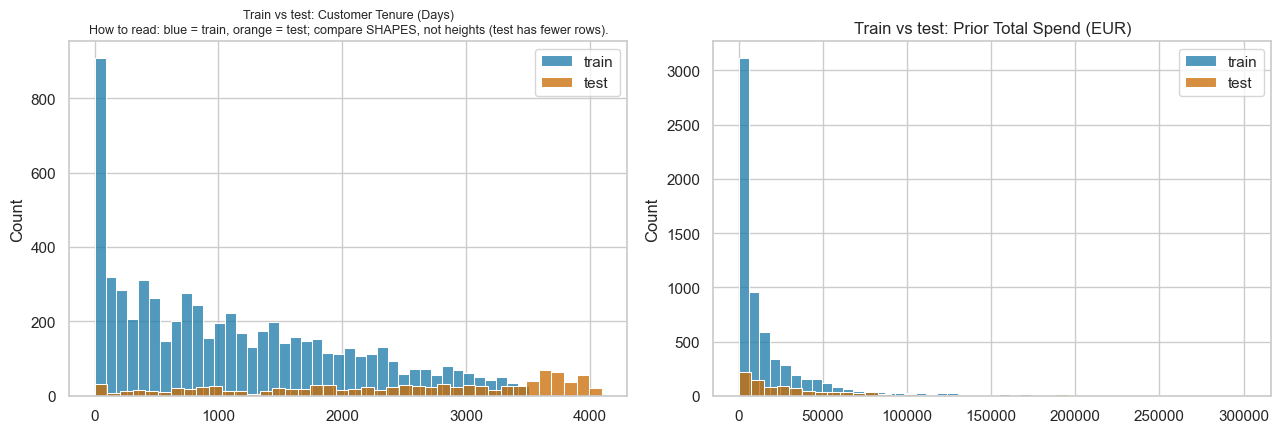


If test customers differ systematically (for example longer tenure or higher spend),
a random CV split can overstate accuracy. NB04 should include a temporal or grouped check.


In [17]:
# CELL 17 - Train vs test: is the test set drawn from the same distribution?
# ks_2samp is not taught, so the comparison is descriptive and covers EVERY numeric feature.
shift = pd.DataFrame({
    "train_mean": train[feature_numeric].mean(),
    "test_mean": test[feature_numeric].mean(),
    "train_std": train[feature_numeric].std(),
})
shift["mean_diff_pct"] = (shift["test_mean"] - shift["train_mean"]) / shift["train_mean"].abs().replace(0, np.nan) * 100
# Percent differences explode when a train mean is near zero (e.g. the noise column), so the
# trustworthy shift measure is the mean gap expressed in train standard deviations.
shift["std_diff"] = (shift["test_mean"] - shift["train_mean"]) / shift["train_std"].replace(0, np.nan)
shift["abs_std_diff"] = shift["std_diff"].abs()
shift = shift.sort_values("abs_std_diff", ascending=False)
shift.insert(0, "label", [clean_label(c) for c in shift.index])
print("=== Train -> test shift for ALL numeric features (sorted by |std_diff|) ===")
print(shift.to_string(float_format=lambda v: "{:,.3f}".format(v)))

# purchase_date is ISO text (YYYY-MM-DD), so lexicographic min/max equals chronological order.
# dropna() first: the column mixes text dates with NaN, and min/max cannot compare str to float.
print("\n=== purchase_date coverage (ISO text) ===")
print("  train:", train["purchase_date"].dropna().min(), "->", train["purchase_date"].dropna().max())
print("  test :", test["purchase_date"].dropna().min(), "->", test["purchase_date"].dropna().max())

# One figure with the full view: every feature, both splits, standardised on TRAIN statistics
# so the two are comparable on a single axis.
zt = ((train[feature_numeric] - mu) / sd).clip(-4, 4)
ze = ((test[feature_numeric] - mu) / sd).clip(-4, 4)
both = pd.concat([zt.assign(split="train"), ze.assign(split="test")])
both_long = pd.melt(both, id_vars="split", var_name="feature", value_name="z_score")
both_long["label"] = [clean_label(f) for f in both_long["feature"]]
fig, ax = plt.subplots(figsize=(9, 11))
sns.boxplot(data=both_long, y="label", x="z_score", hue="split", orient="h",
            palette=[PLOT_BLUE, PLOT_ORANGE], ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Train vs test, ALL numeric features (standardised on train)")
ax.set_xlabel("z-score (train mean = 0, train sd = 1, clipped at +/-4 for display)")
ax.set_ylabel("")
plt.setp(ax.get_yticklabels(), fontsize=8)
ax.legend()
guide(ax, "How to read: blue = train, orange = test, both in train sd; a shifted orange box = drift.")
plt.savefig(FIG_DIR / "nb01_08_drift_boxplots.png", dpi=200)
plt.tight_layout()
plt.show()

# The taught overlaid histogram, for the two largest shifts in the table above (a rule, not a
# preference). Test holds far fewer rows, so compare SHAPES, not bar heights.
drift_cols = shift.index[:2].tolist()
print("\nOverlaid histograms for the two largest |std_diff|:", [clean_label(c) for c in drift_cols])
print("Note: test holds ~{:.1f}x fewer rows than train, so compare distribution SHAPES, not heights.".format(
    len(train) / len(test)))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axes, drift_cols):
    sns.histplot(train[col].dropna(), bins=40, color=PLOT_BLUE, label="train", ax=ax)
    sns.histplot(test[col].dropna(), bins=40, color=PLOT_ORANGE, label="test", ax=ax)
    ax.set_title("Train vs test: " + clean_label(col))
    ax.set_xlabel("")  # the title already names the feature
    ax.legend()
guide(axes[0], "How to read: blue = train, orange = test; compare SHAPES, not heights (test has fewer rows).")
plt.savefig(FIG_DIR / "nb01_09_drift_histograms.png", dpi=200)
plt.tight_layout()
plt.show()

print("\nIf test customers differ systematically (for example longer tenure or higher spend),")
print("a random CV split can overstate accuracy. NB04 should include a temporal or grouped check.")

### Cell 18 - Takeaways
**Purpose.** State the conclusions once, computed from the objects above so they cannot go stale.
**Look at.** Every decision that Notebook 02 must execute is listed here with its reason.

In [18]:
# CELL 18 - Key takeaways (auto-computed so they never go stale).
n_missing_cols = int((train.isna().sum() > 0).sum())
print("=== EDA SUMMARY ===")
print("1. Size: train={:,} rows, test={:,} rows; unit = one transaction; {:,} unique customers.".format(
    len(train), len(test), train["customer_id"].nunique()))
print("2. Balance: {:.1f}% positive / {:.1f}% negative (minority-majority ratio {:.2f}) -> close to".format(
    share.loc[1] * 100, share.loc[0] * 100, balance_ratio))
print("   balanced, NOT imbalanced; majority baseline {:.1f}%; optimise F1 (Kaggle metric).".format(baseline * 100))
print("3. Missing: {} columns contain nulls; {} train rows are structurally empty (drop in NB02).".format(
    n_missing_cols, len(empty_rows)))
print("4. Invalid values: 1e9 sentinels and impossible negatives -> set to NaN + flag in NB02.")
print("5. Strongest numeric signals: {}.".format(", ".join(clean_label(f) for f in assoc.head(3)["feature"])))
print("6. Strongest categorical signal: {} (Cramer's V={:.3f}).".format(
    clean_label(cat_df["feature"].tolist()[0]), cat_df["cramers_v"].tolist()[0]))
print("7. Redundant predictor pairs (|r| >= 0.80): {} -> prune in NB03.".format(len(pairs_df)))
best_col, best_dev = max(((c, t["dev_pp"].max()) for c, t in tables.items()), key=lambda t: t[1])
print("8. clientes carries real signal: largest trusted deviation {:.1f} pp in {}; settle keep/drop".format(
    best_dev, clean_label(best_col)))
print("   by ablation in NB04 (the old 'adds little' line was an assumption).")
print("9. Train vs test drift exists (Cell 17); prefer temporal/grouped validation in NB04.")
print("10. {} is a planted noise column (near-zero association) -> drop in NB02/NB03.".format(
    clean_label("random_noise")))

=== EDA SUMMARY ===
1. Size: train=6,534 rows, test=986 rows; unit = one transaction; 610 unique customers.
2. Balance: 55.9% positive / 44.1% negative (minority-majority ratio 0.79) -> close to
   balanced, NOT imbalanced; majority baseline 55.9%; optimise F1 (Kaggle metric).
3. Missing: 36 columns contain nulls; 65 train rows are structurally empty (drop in NB02).
4. Invalid values: 1e9 sentinels and impossible negatives -> set to NaN + flag in NB02.
5. Strongest numeric signals: Purchase Count (Past 365d), Purchase Count (Past 180d), Purchase Count (Past 90d).
6. Strongest categorical signal: Transport Method (Cramer's V=0.290).
7. Redundant predictor pairs (|r| >= 0.80): 16 -> prune in NB03.
8. clientes carries real signal: largest trusted deviation 38.5 pp in Commercial Region; settle keep/drop
   by ablation in NB04 (the old 'adds little' line was an assumption).
9. Train vs test drift exists (Cell 17); prefer temporal/grouped validation in NB04.
10. Random Noise (planted) is a p

### Cell 19 - Handover
**Purpose.** Write the raw frames for Notebook 02 as CSV, because pickle is not in the toolkit.
**Look at.** The three file names, and the note that `sample_submission.csv` is deliberately not
re-saved: it is an input template, not an output.

In [19]:
# CELL 19 - Persist the raw frames for Notebook 02 (CSV only; pickle is not in the toolkit).
# sample_submission.csv is NOT re-saved: it is a read-only instructor template, not our output.
train.to_csv(DATA_DIR / "train_raw.csv", index=False)
test.to_csv(DATA_DIR / "test_raw.csv", index=False)
clientes.to_csv(DATA_DIR / "clientes_raw.csv", index=False)
print("Saved to", DATA_DIR)
print("  train_raw.csv, test_raw.csv, clientes_raw.csv")
print("Notebook 02 reads these CSVs (not pickles).")

Saved to C:\Users\Mohamed_Triki\Desktop\Projets\machine_learning\ML_Group_22\data
  train_raw.csv, test_raw.csv, clientes_raw.csv
Notebook 02 reads these CSVs (not pickles).


---

## Where this notebook leaves the project

**Produced.** `data/train_raw.csv`, `data/test_raw.csv`, `data/clientes_raw.csv` - the raw frames,
unchanged apart from being handed over as CSV, plus nine figures in `artifacts/figures/`.

**Conclusions Notebook 02 must act on**

| Finding | Action in Notebook 02 |
|---|---|
| 65 train rows with every transaction field null | dropped, train only |
| 1e9 placeholders and impossible negatives | converted to NaN plus an indicator flag |
| `prior_*` nulls are structural (first-time and single-purchase buyers) | filled 0 plus a history flag, not imputed |
| `transport_method` with 80 levels, 59 below 1% support | rare levels grouped into `Other` |
| `clientes` attributes carry real signal | joined on `customer_id`; free text dropped |
| Test rows are later and longer-tenured | no test information used when fitting; validated by time in Notebook 04 |

**Next: Notebook 02 - Clean & Preprocess.** It reads the three CSVs above, applies exactly those
decisions, encodes and scales, and writes `data/train_clean.csv` and `data/test_clean.csv`.
Run the notebooks in order: 01 explore, 02 clean, 03 select, 04 model and submit.